### 1. Import libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.impute import SimpleImputer
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, classification_report, confusion_matrix, ConfusionMatrixDisplay, RocCurveDisplay
from lightgbm import LGBMClassifier
from xgboost import XGBClassifier

sns.set_theme(style="whitegrid")


### 2. Load the dataset

In [2]:
df = pd.read_csv("diabetes.csv")

df.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


### 3. Check the data

In [3]:
print("Shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())
print("\nData types:")
print(df.dtypes)
print("\nMissing values:")
print(df.isnull().sum())
print("\nDuplicate rows:", df.duplicated().sum())

Shape: (768, 9)

Column names:
['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI', 'DiabetesPedigreeFunction', 'Age', 'Outcome']

Data types:
Pregnancies                   int64
Glucose                       int64
BloodPressure                 int64
SkinThickness                 int64
Insulin                       int64
BMI                         float64
DiabetesPedigreeFunction    float64
Age                           int64
Outcome                       int64
dtype: object

Missing values:
Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64

Duplicate rows: 0


### 4. Summary statistics

In [4]:
df.describe()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000
mean,3.845052,120.894531,69.105469,20.536458,79.799479,31.992578,0.471876,33.240885,0.348958
std,3.369578,31.972618,19.355807,15.952218,115.244002,7.884160,0.331329,11.760232,0.476951
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.078000,21.000000,0.000000
25%,1.000000,99.000000,62.000000,0.000000,0.000000,27.300000,0.243750,24.000000,0.000000
50%,3.000000,117.000000,72.000000,23.000000,30.500000,32.000000,0.372500,29.000000,0.000000
75%,6.000000,140.250000,80.000000,32.000000,127.250000,36.600000,0.626250,41.000000,1.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000


### 5. Check the target distribution

Outcome
0    500
1    268
Name: count, dtype: int64


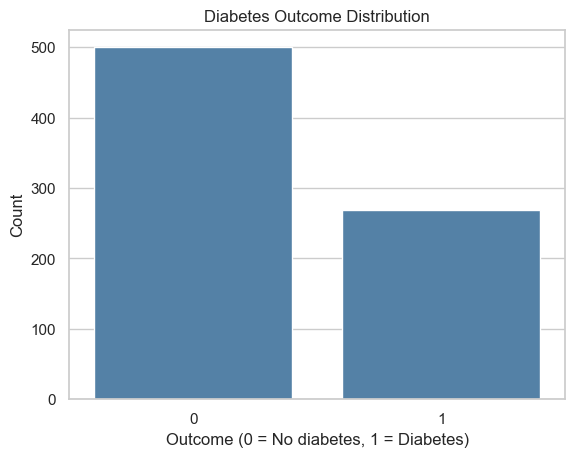

In [5]:
print(df["Outcome"].value_counts())
sns.countplot(data=df, x="Outcome", color="steelblue")
plt.title("Diabetes Outcome Distribution")
plt.xlabel("Outcome (0 = No diabetes, 1 = Diabetes)")
plt.ylabel("Count")
plt.show()

### 6. Histograms

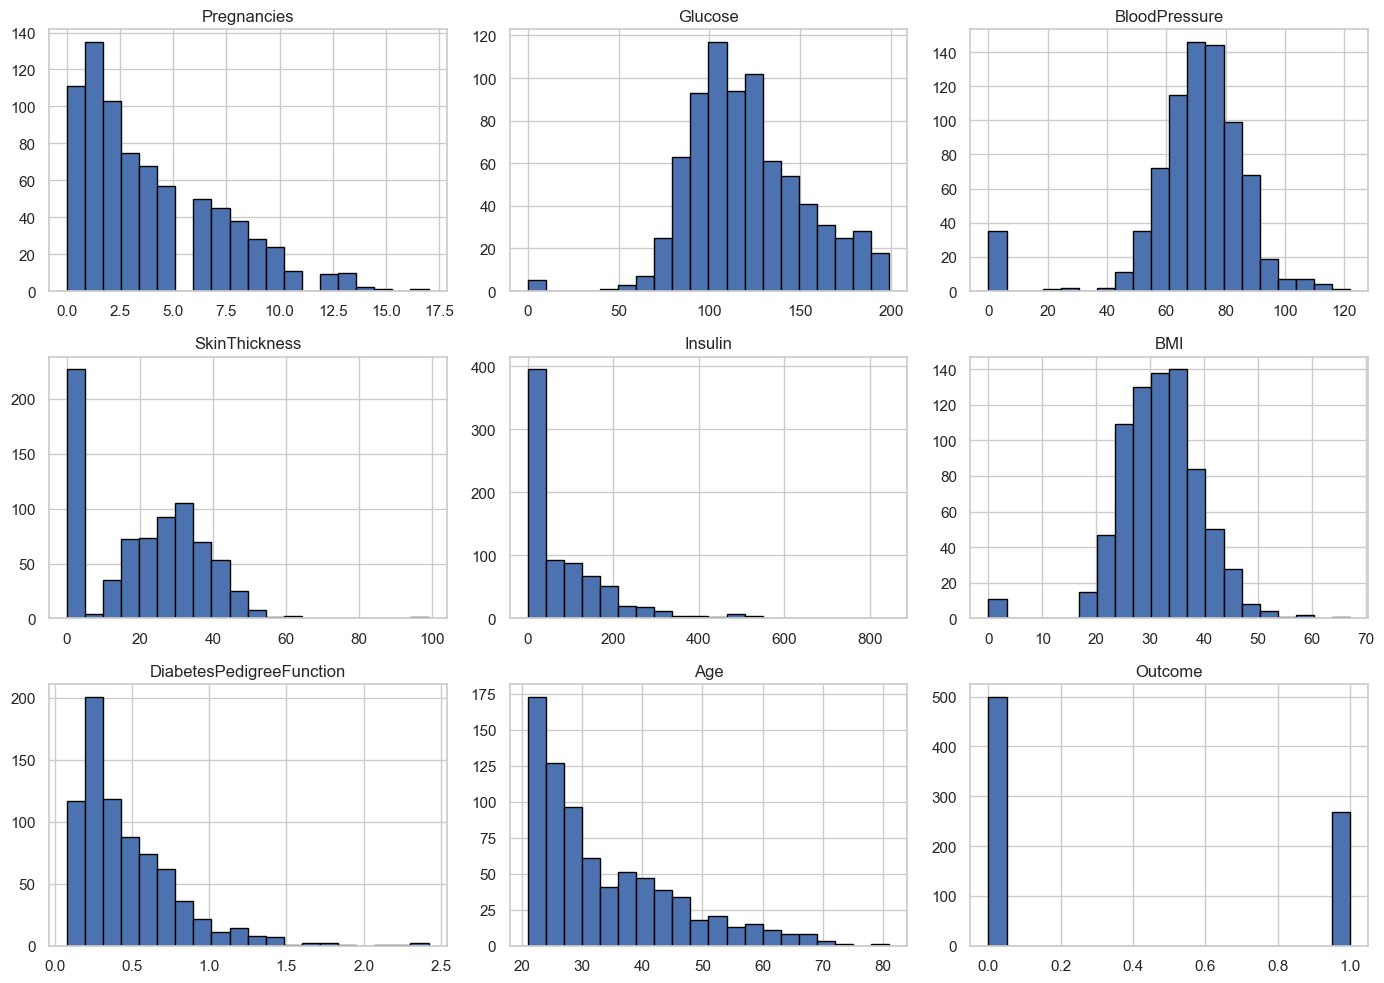

In [6]:
df.hist(figsize=(14, 10), bins=20, edgecolor="black")
plt.tight_layout()
plt.show()

### 7. Box plots

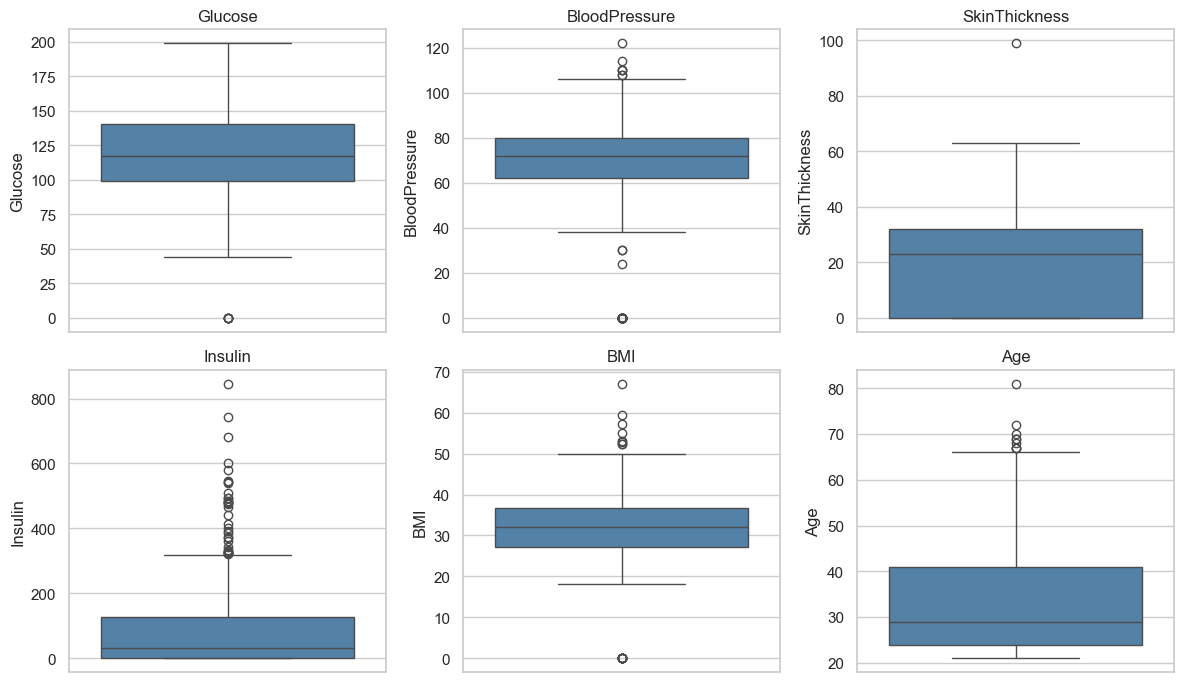

In [7]:
columns_to_plot = ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI", "Age"]

plt.figure(figsize=(12, 7))
for i, column in enumerate(columns_to_plot, 1):
    plt.subplot(2, 3, i)
    sns.boxplot(y=df[column], color="steelblue")
    plt.title(column)
plt.tight_layout()
plt.show()

### 8. Correlation between features

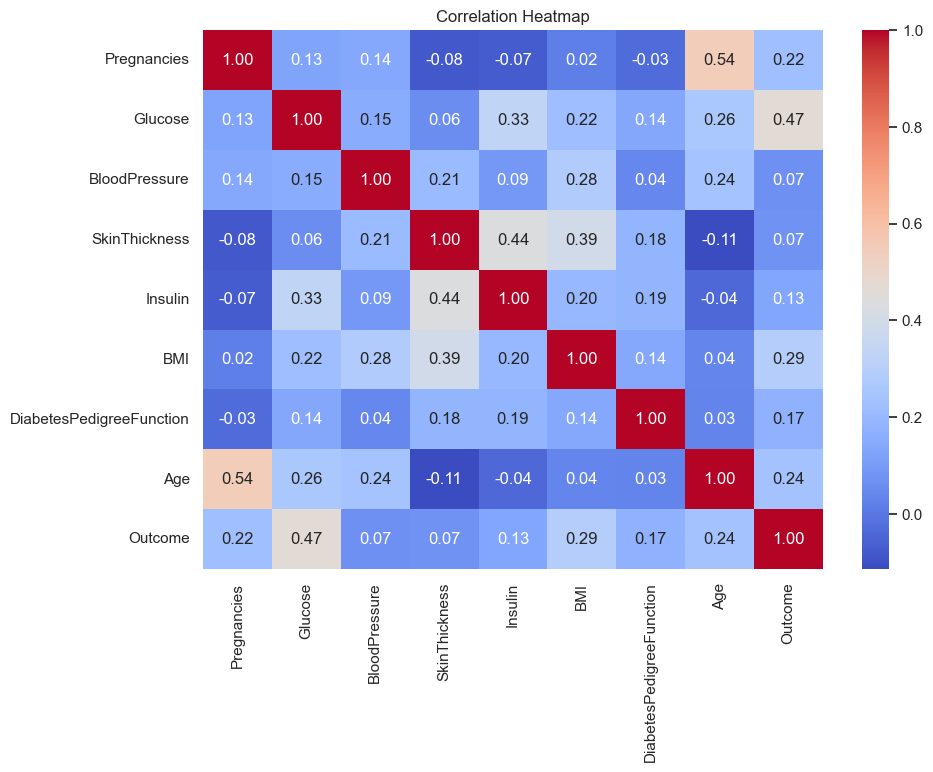

In [8]:
plt.figure(figsize=(10, 7))
sns.heatmap(df.corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Heatmap")
plt.show()

### 9. Compare a few features with the outcome

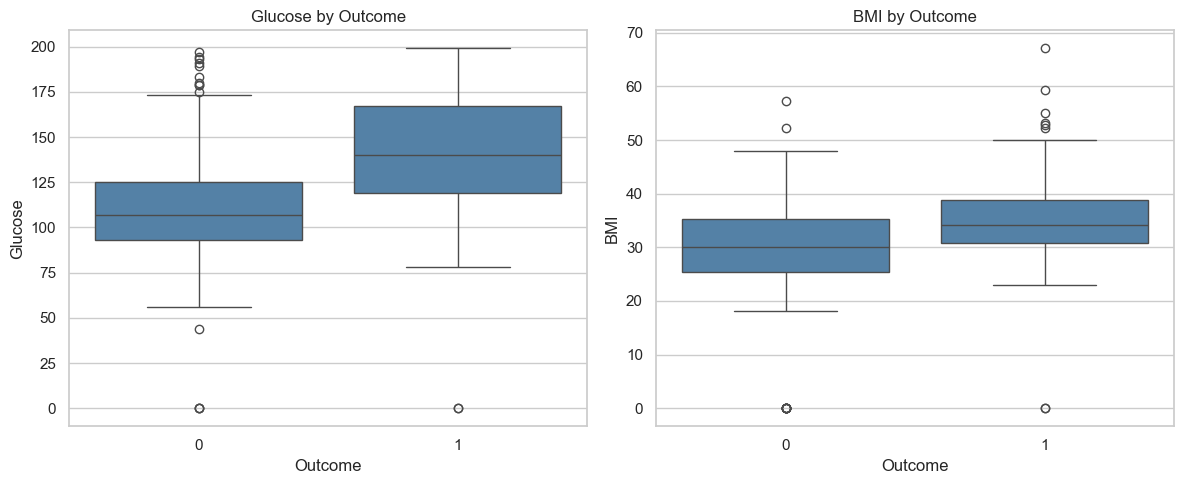

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
sns.boxplot(data=df, x="Outcome", y="Glucose", ax=axes[0], color="steelblue")
axes[0].set_title("Glucose by Outcome")
sns.boxplot(data=df, x="Outcome", y="BMI", ax=axes[1], color="steelblue")
axes[1].set_title("BMI by Outcome")
plt.tight_layout()
plt.show()

### 10. Scatter plot

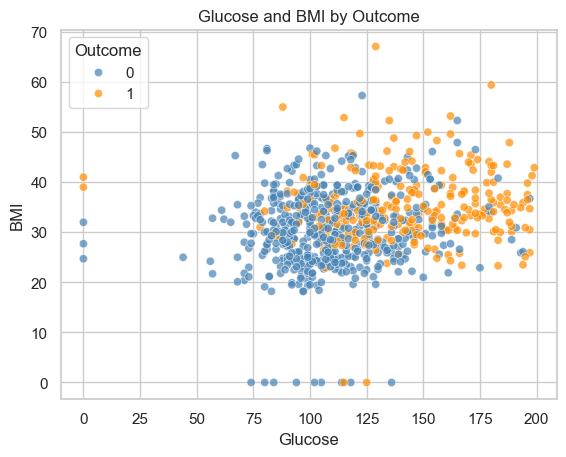

In [10]:
sns.scatterplot(data=df, x="Glucose", y="BMI", hue="Outcome", palette={0: "steelblue", 1: "darkorange"}, alpha=0.7)
plt.title("Glucose and BMI by Outcome")
plt.show()

### 11. Prepare the data

There are no blank cells in the file, but zero values in some medical measurements can mean that the measurement was not recorded. I replace zero with missing values for those columns and fill them with the median. The other zero values, such as pregnancies, are kept.

In [11]:
df_model = df.copy()
zero_columns = ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"]
df_model[zero_columns] = df_model[zero_columns].replace(0, np.nan)

df_model[zero_columns].isnull().sum()

Glucose            5
BloodPressure     35
SkinThickness    227
Insulin          374
BMI               11
dtype: int64

### 12. Split the features and target

In [12]:
X = df_model.drop(columns="Outcome")
y = df_model["Outcome"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Training rows:", X_train.shape[0])
print("Testing rows:", X_test.shape[0])
print("\nTraining target distribution:")
print(y_train.value_counts())

Training rows: 614
Testing rows: 154

Training target distribution:
Outcome
0    400
1    214
Name: count, dtype: int64


### 13. Fill missing values

In [13]:
imputer = SimpleImputer(strategy="median")
X_train = pd.DataFrame(imputer.fit_transform(X_train), columns=X_train.columns, index=X_train.index)
X_test = pd.DataFrame(imputer.transform(X_test), columns=X_test.columns, index=X_test.index)

print("Missing values in training data:", X_train.isnull().sum().sum())
print("Missing values in testing data:", X_test.isnull().sum().sum())

Missing values in training data: 0
Missing values in testing data: 0


### 14. Handle the class imbalance

The outcome classes are not equal in size. I use class weights for LightGBM and `scale_pos_weight` for XGBoost so the smaller positive class gets more attention. These are tree models, so feature scaling is not required. All feature columns are already numeric, so encoding is not needed.

In [14]:
class_ratio = (y_train == 0).sum() / (y_train == 1).sum()
print("Negative to positive class ratio:", round(class_ratio, 2))

Negative to positive class ratio: 1.87


### 15. Train the LightGBM model

In [15]:
lgb_model = LGBMClassifier(
    n_estimators=150,
    learning_rate=0.05,
    class_weight="balanced",
    random_state=42,
    verbosity=-1,
    n_jobs=1
)

lgb_model.fit(X_train, y_train)
lgb_pred = lgb_model.predict(X_test)
lgb_prob = lgb_model.predict_proba(X_test)[:, 1]

### 16. Train the XGBoost model

In [16]:
xgb_model = XGBClassifier(
    n_estimators=150,
    max_depth=3,
    learning_rate=0.05,
    subsample=0.9,
    colsample_bytree=0.9,
    scale_pos_weight=class_ratio,
    eval_metric="logloss",
    random_state=42,
    n_jobs=1
)

xgb_model.fit(X_train, y_train)
xgb_pred = xgb_model.predict(X_test)
xgb_prob = xgb_model.predict_proba(X_test)[:, 1]

### 17. Evaluate both models

In [17]:
def get_scores(name, y_true, y_pred, y_prob):
    return {
        "Model": name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Recall": recall_score(y_true, y_pred, zero_division=0),
        "F1-score": f1_score(y_true, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_true, y_prob)
    }

baseline_scores = pd.DataFrame([
    get_scores("LightGBM", y_test, lgb_pred, lgb_prob),
    get_scores("XGBoost", y_test, xgb_pred, xgb_prob)
])

baseline_scores.round(3)

,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,LightGBM,0.773,0.673,0.685,0.679,0.825
1,XGBoost,0.734,0.597,0.741,0.661,0.824


### 18. Classification reports

In [18]:
print("LightGBM")
print(classification_report(y_test, lgb_pred, zero_division=0))
print("XGBoost")
print(classification_report(y_test, xgb_pred, zero_division=0))

LightGBM
              precision    recall  f1-score   support

           0       0.83      0.82      0.82       100
           1       0.67      0.69      0.68        54

    accuracy                           0.77       154
   macro avg       0.75      0.75      0.75       154
weighted avg       0.77      0.77      0.77       154

XGBoost
              precision    recall  f1-score   support

           0       0.84      0.73      0.78       100
           1       0.60      0.74      0.66        54

    accuracy                           0.73       154
   macro avg       0.72      0.74      0.72       154
weighted avg       0.75      0.73      0.74       154



### 19. Confusion matrices

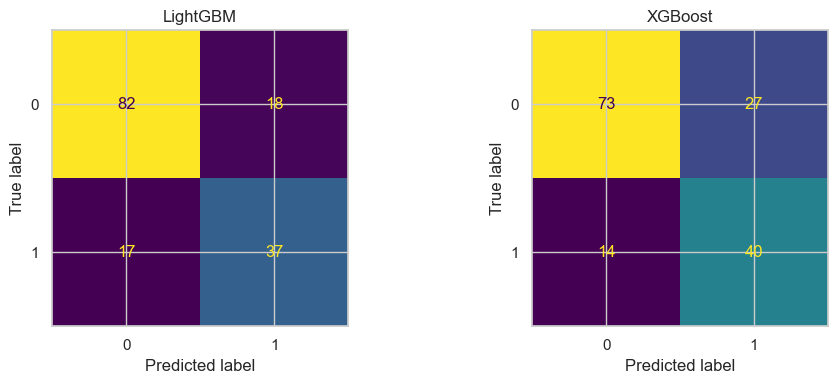

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
ConfusionMatrixDisplay.from_predictions(y_test, lgb_pred, ax=axes[0], colorbar=False)
axes[0].set_title("LightGBM")
ConfusionMatrixDisplay.from_predictions(y_test, xgb_pred, ax=axes[1], colorbar=False)
axes[1].set_title("XGBoost")
plt.tight_layout()
plt.show()

### 20. ROC curves

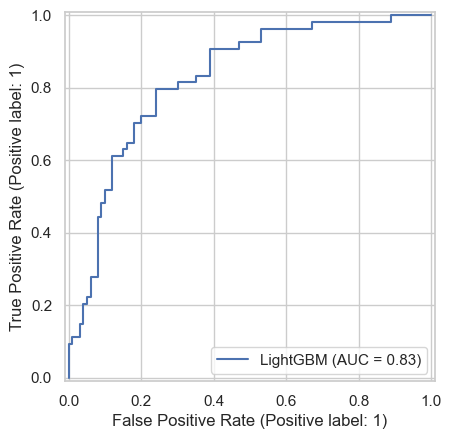

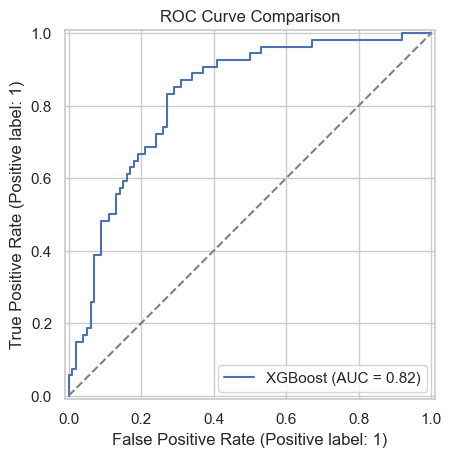

In [20]:
RocCurveDisplay.from_predictions(y_test, lgb_prob, name="LightGBM")
RocCurveDisplay.from_predictions(y_test, xgb_prob, name="XGBoost")
plt.plot([0, 1], [0, 1], linestyle="--", color="gray")
plt.title("ROC Curve Comparison")
plt.show()

### 21. Hyperparameter tuning

Grid search with stratified cross-validation is used to compare a few parameter combinations. F1-score is used for selection because the target classes are imbalanced.

In [21]:
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)

lgb_params = {
    "n_estimators": [100, 200],
    "max_depth": [-1, 5],
    "num_leaves": [15, 31]
}

lgb_search = GridSearchCV(
    LGBMClassifier(class_weight="balanced", random_state=42, verbosity=-1, n_jobs=1),
    param_grid=lgb_params,
    scoring="f1",
    cv=cv,
    n_jobs=1
)
lgb_search.fit(X_train, y_train)

print("Best LightGBM parameters:")
print(lgb_search.best_params_)
print("Best cross-validation F1-score:", round(lgb_search.best_score_, 3))

Best LightGBM parameters:
{'max_depth': 5, 'n_estimators': 100, 'num_leaves': 31}
Best cross-validation F1-score: 0.66


In [22]:
xgb_params = {
    "n_estimators": [100, 200],
    "max_depth": [3, 5],
    "learning_rate": [0.05, 0.1]
}

xgb_search = GridSearchCV(
    XGBClassifier(
        scale_pos_weight=class_ratio,
        eval_metric="logloss",
        random_state=42,
        n_jobs=1
    ),
    param_grid=xgb_params,
    scoring="f1",
    cv=cv,
    n_jobs=1
)
xgb_search.fit(X_train, y_train)

print("Best XGBoost parameters:")
print(xgb_search.best_params_)
print("Best cross-validation F1-score:", round(xgb_search.best_score_, 3))

Best XGBoost parameters:
{'learning_rate': 0.05, 'max_depth': 3, 'n_estimators': 100}
Best cross-validation F1-score: 0.693


### 22. Evaluate the tuned models

In [23]:
best_lgb = lgb_search.best_estimator_
best_xgb = xgb_search.best_estimator_

best_lgb_pred = best_lgb.predict(X_test)
best_lgb_prob = best_lgb.predict_proba(X_test)[:, 1]
best_xgb_pred = best_xgb.predict(X_test)
best_xgb_prob = best_xgb.predict_proba(X_test)[:, 1]

final_scores = pd.DataFrame([
    get_scores("Tuned LightGBM", y_test, best_lgb_pred, best_lgb_prob),
    get_scores("Tuned XGBoost", y_test, best_xgb_pred, best_xgb_prob)
])

final_scores.round(3)

,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,Tuned LightGBM,0.753,0.638,0.685,0.661,0.821
1,Tuned XGBoost,0.753,0.618,0.778,0.689,0.814


### 23. Compare the tuned results

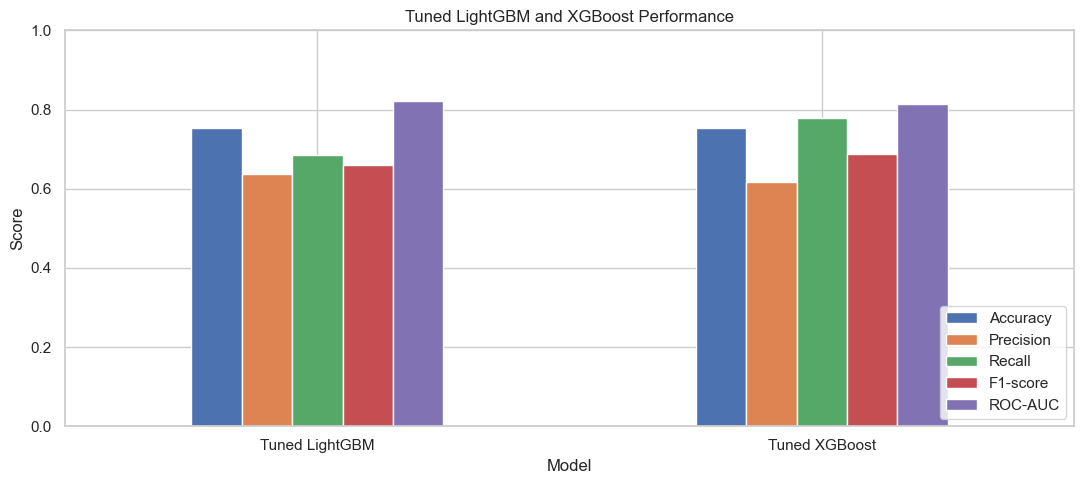

In [24]:
plot_scores = final_scores.set_index("Model")[["Accuracy", "Precision", "Recall", "F1-score", "ROC-AUC"]]
plot_scores.plot(kind="bar", figsize=(11, 5), ylim=(0, 1))
plt.title("Tuned LightGBM and XGBoost Performance")
plt.ylabel("Score")
plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

### 24. Feature importance

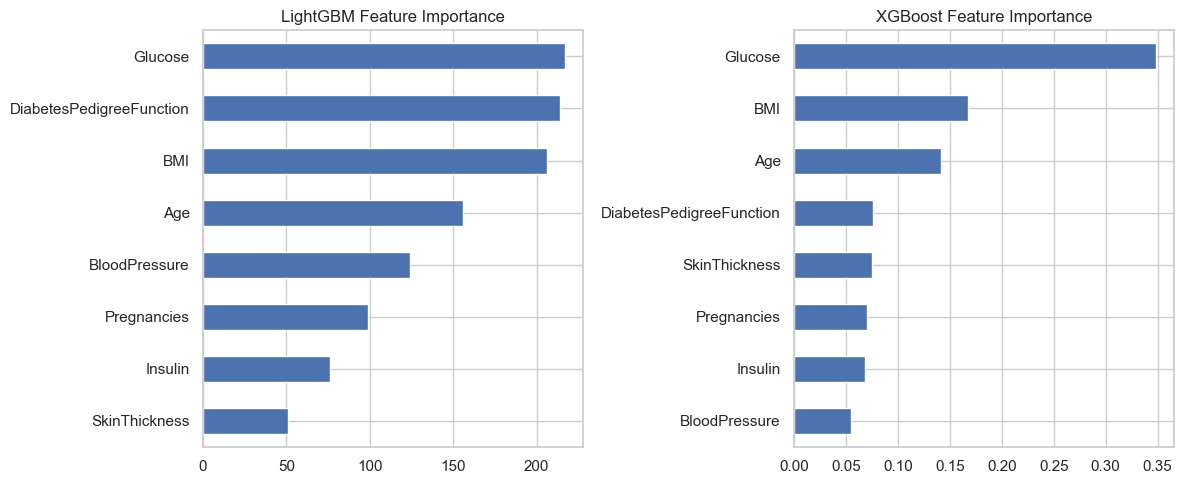

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

lgb_importance = pd.Series(best_lgb.feature_importances_, index=X_train.columns).sort_values()
lgb_importance.plot(kind="barh", ax=axes[0])
axes[0].set_title("LightGBM Feature Importance")

xgb_importance = pd.Series(best_xgb.feature_importances_, index=X_train.columns).sort_values()
xgb_importance.plot(kind="barh", ax=axes[1])
axes[1].set_title("XGBoost Feature Importance")

plt.tight_layout()
plt.show()

### 25. Best model and short report

In [26]:
best_row = final_scores.sort_values("F1-score", ascending=False).iloc[0]
print("Best model based on test F1-score:", best_row["Model"])
print("Accuracy:", round(best_row["Accuracy"], 3))
print("Precision:", round(best_row["Precision"], 3))
print("Recall:", round(best_row["Recall"], 3))
print("F1-score:", round(best_row["F1-score"], 3))
print("ROC-AUC:", round(best_row["ROC-AUC"], 3))

print("\nReport:")
print("LightGBM and XGBoost were trained on the diabetes dataset and compared using the same train-test split.")
print("Median imputation was used for missing medical measurements, and class weighting was used to address the imbalance in Outcome.")
print("The better model for this test set is the one with the higher F1-score, while precision and recall show the balance of positive predictions and correctly identified positive cases.")
print("This model is for learning purposes and should not be used to make medical decisions.")

Best model based on test F1-score: Tuned XGBoost
Accuracy: 0.753
Precision: 0.618
Recall: 0.778
F1-score: 0.689
ROC-AUC: 0.814

Report:
LightGBM and XGBoost were trained on the diabetes dataset and compared using the same train-test split.
Median imputation was used for missing medical measurements, and class weighting was used to address the imbalance in Outcome.
The better model for this test set is the one with the higher F1-score, while precision and recall show the balance of positive predictions and correctly identified positive cases.
This model is for learning purposes and should not be used to make medical decisions.
